# Dependances

In [117]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
#from tensorflow.keras.models import Sequential
#from tensorflow.keras.layers import LSTM, Dropout, Dense, BatchNormalization
#from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import r2_score, mean_absolute_error
from torch.utils.data import DataLoader, TensorDataset

#import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import seaborn as sns

device = torch.device("cuda")  # Définit le GPU comme appareil

# Data

- 400+ cryptos, 1 minute resolution : https://www.kaggle.com/datasets/tencars/392-crypto-currency-pairs-at-minute-resolution?resource=download

In [118]:
df = pd.read_csv('datams.csv')

Suppression des crypto's avec moins d'[Hours] heures de données

In [119]:
hours = 48

block_counts = df.groupby('crypto')['block'].count()
print(sum(block_counts < hours)) #1 mois c'est 43 200

#cryptos_to_drop = block_counts[block_counts < hours].index
#df = df[~df["crypto"].isin(cryptos_to_drop)]

#print(f"Nombre de cryptos supprimées : {len(cryptos_to_drop)}")
#print(f"Taille du DataFrame filtré : {df.shape}")

0


# Entrainement Transformer

## Embedding

Nous devons creer des embedding afin d'apprendre au modele que chaque crypto peut agir d'une maniere différente

### Attribution d'un ID unique à chaque paire

In [120]:
crypto_mapping = {crypto: idx for idx, crypto in enumerate(df['crypto'].unique())}

df['crypto_id'] = df['crypto'].map(crypto_mapping)
df.head()

,crypto,block,open,close,high,low,volume,crypto_id
0,1inch-usd,1.628984e+12,3.0473,3.0337,3.0473,3.0256,1181.533217,0
1,1inch-usd,1.628987e+12,3.0242,3.0375,3.0375,3.0065,27.623659,0
2,1inch-usd,1.628991e+12,3.0580,3.0811,3.0845,3.0580,27.753915,0
3,1inch-usd,1.628994e+12,3.0694,3.0607,3.0694,3.0586,86.379213,0
4,1inch-usd,1.628998e+12,3.0068,3.0266,3.0266,3.0053,631.110223,0


### Standardisation et séparation des données

By normalizing the data after splitting, we maintain the integrity of the testing set as an unbiased evaluation metric.

In [121]:
''' Selection des ensembles à partir des indices '''
train_indices, test_indices = train_test_split(df.index.values, test_size=0.2, random_state=42, shuffle=False)

X_train, X_test = df.loc[train_indices, ['open', 'high', 'low', 'volume']].values, df.loc[test_indices, ['open', 'high', 'low', 'volume']].values
y_train, y_test = df.loc[train_indices, 'close'].values, df.loc[test_indices, 'close'].values

''' Standardisation '''
scaler_training, scaler_test = RobustScaler(), RobustScaler()
X_train_scaled, y_train_scaled = scaler_training.fit_transform(X_train), scaler_test.fit_transform(y_train.reshape(-1, 1))
X_test_scaled,y_test_scaled = scaler_training.transform(X_test), scaler_test.transform(y_test.reshape(-1, 1))

''' Conversion en Tensor'''
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train_scaled[1:], dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test_scaled[1:], dtype=torch.float32).to(device)
X_train_tensor = X_train_tensor[:-1]
X_test_tensor = X_test_tensor[:-1]

''' Création de la couche d'embedding'''
crypto_embedding = nn.Embedding(num_embeddings=len(crypto_mapping), embedding_dim=8).to(device)


# Identifiants des cryptos
crypto_ids_train = torch.tensor(df.loc[train_indices, 'crypto_id'].values, dtype=torch.long).to(device)
crypto_ids_test = torch.tensor(df.loc[test_indices, 'crypto_id'].values, dtype=torch.long).to(device)
crypto_ids_train = crypto_ids_train[:-1]
crypto_ids_test = crypto_ids_test[:-1]

# Association des embeddings aux ID's
embedded_cryptos_train = crypto_embedding(crypto_ids_train)
embedded_cryptos_test = crypto_embedding(crypto_ids_test)

# Concaténer les données normalisées avec les embeddings
X_train_final = torch.cat([X_train_tensor, embedded_cryptos_train], dim=1)
X_test_final = torch.cat([X_test_tensor, embedded_cryptos_test], dim=1)

print(crypto_embedding.weight.shape)
print(X_train_final.size())
print(X_test_final.size())

torch.Size([760, 8])
torch.Size([921810, 12])
torch.Size([230452, 12])


## Construction du modèle

In [122]:
input_dim = X_train_final.size(1)
output_dim = 1

# Création du modèle
model = nn.Sequential(
    nn.Linear(input_dim, 256), # Couche linéaire avec 128 neurones
    nn.ReLU(),                 # Activation ReLU
    nn.Dropout(0.3),           # Dropout pour régularisation
    nn.Linear(256, 128),        # Couche cachée
    nn.ReLU(),
    nn.Linear(128, output_dim)  # Couche de sortie
).to(device)

criterion = nn.MSELoss()  # Perte MSE pour la régression
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)  # Optimiseur Adam

epochs = 100

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    y_pred = model(X_train_final)
    loss = criterion(y_pred, y_train_tensor)
    loss.backward(retain_graph=True)
    optimizer.step()

    print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss.item()}")

Epoch 1/100, Loss: 249058240.0
Epoch 2/100, Loss: 199269280.0
Epoch 3/100, Loss: 154798784.0
Epoch 4/100, Loss: 115573368.0
Epoch 5/100, Loss: 81813624.0
Epoch 6/100, Loss: 53628356.0
Epoch 7/100, Loss: 31568638.0
Epoch 8/100, Loss: 15324600.0
Epoch 9/100, Loss: 5706822.5
Epoch 10/100, Loss: 2709156.0
Epoch 11/100, Loss: 5201440.0
Epoch 12/100, Loss: 10640545.0
Epoch 13/100, Loss: 16474801.0
Epoch 14/100, Loss: 20508872.0
Epoch 15/100, Loss: 21355828.0
Epoch 16/100, Loss: 19581704.0
Epoch 17/100, Loss: 16903776.0
Epoch 18/100, Loss: 12468195.0
Epoch 19/100, Loss: 8784798.0
Epoch 20/100, Loss: 5537563.5
Epoch 21/100, Loss: 3368624.25
Epoch 22/100, Loss: 2166388.0
Epoch 23/100, Loss: 1621152.75
Epoch 24/100, Loss: 2108551.75
Epoch 25/100, Loss: 2700464.75
Epoch 26/100, Loss: 3430881.25
Epoch 27/100, Loss: 4038726.5
Epoch 28/100, Loss: 4816856.0
Epoch 29/100, Loss: 5082592.0
Epoch 30/100, Loss: 4867899.0
Epoch 31/100, Loss: 4785755.0
Epoch 32/100, Loss: 4322026.5
Epoch 33/100, Loss: 37228

In [123]:
# Transformer Encoder
transformer = nn.Transformer(
    d_model=X_train_final.size(-1),  # Taille des features d'entrée
    nhead=4,  # Nombre de têtes d'attention
    num_encoder_layers=2,  # Nombre de couches
    dim_feedforward=64  # Taille des couches feedforward
)

x_transformed = transformer(X_train_final)  # Shape : [batch_size, seq_len, d_model]


C:\Users\utilisateur\AppData\Roaming\Python\Python312\site-packages\torch\nn\modules\transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


TypeError: Transformer.forward() missing 1 required positional argument: 'tgt'

Paramettres

In [124]:
model.eval()

with torch.no_grad():
    test_predictions = model(X_test_final)
    test_loss = criterion(test_predictions, y_test_tensor)

test_predictions = test_predictions.cpu().detach().numpy()
y_test_original = scaler_test.inverse_transform(y_test_tensor.cpu().detach().numpy())
r2 = r2_score(y_test_original, test_predictions)

mae = mean_absolute_error(y_test_original, test_predictions)

print(f"Test Loss: {test_loss.item():.4f}")
print(f"R^2 Score: {r2:.4f}")
print(f"Mean Absolute Error: {mae:.4f}")

print("Mean of y_train_scaled:", y_train_scaled.mean())
print("Std of y_train_scaled:", y_train_scaled.std())

print("Mean of x_train_scaled:", X_train_scaled.mean())
print("Std of x_train_scaled:", X_train_scaled.std())


Test Loss: 71.0384
R^2 Score: 0.0261
Mean Absolute Error: 2028.6519
Mean of y_train_scaled: 1297.517403222553
Std of y_train_scaled: 14396.341410398516
Mean of x_train_scaled: 997.4261533644409
Std of x_train_scaled: 13004.443053301562


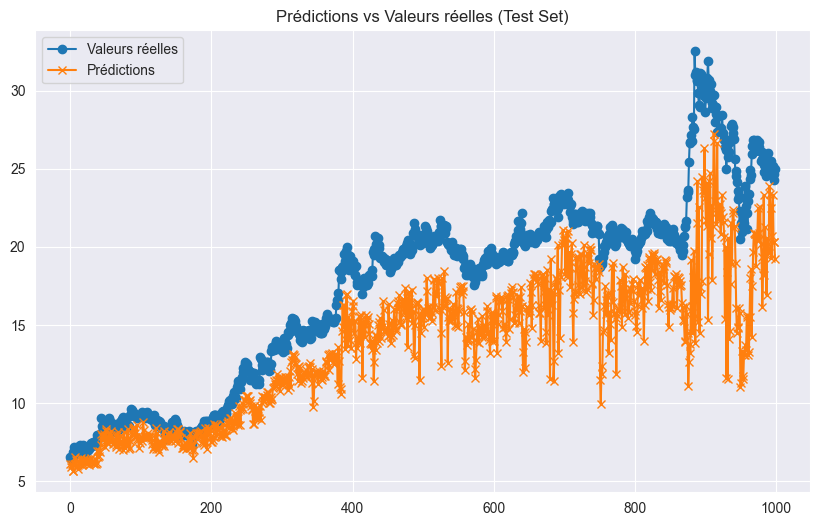

In [125]:
if isinstance(test_predictions, torch.Tensor):
    test_predictions_numpy = test_predictions.cpu().numpy()  # Convertir en NumPy si nécessaire
else:
    test_predictions_numpy = test_predictions

if isinstance(y_test_tensor, torch.Tensor):
    y_test_numpy = y_test_tensor.cpu().numpy()  # Convertir en NumPy si nécessaire
else:
    y_test_numpy = y_test_tensor

# Inverser la normalisation pour les données originales
test_predictions_original = scaler_test.inverse_transform(test_predictions_numpy)
y_test_original = scaler_test.inverse_transform(y_test_numpy)

# Tracer les valeurs réelles vs prédictions
plt.figure(figsize=(10, 6))
plt.plot(y_test_original[:1000], label='Valeurs réelles', marker='o')  # Les 100 premières valeurs réelles
plt.plot(test_predictions_original[:1000], label='Prédictions', marker='x')  # Les 100 premières prédictions
plt.legend()
plt.title("Prédictions vs Valeurs réelles (Test Set)")
plt.show()


# LSTM

In [121]:
"""w_size = 48

'''Fonction pour créer des séquences temporelles de plusieurs heure'''

def create_sequences(data, target, w_size):

    sequences, targets = [], []
    for i in range(len(data) - w_size):
        sequences.append(data[i:i+w_size]) #X
        targets.append(target[i+w_size]) #Y
    return np.array(sequences), np.array(targets)

#
X = df[['open', 'close', 'high', 'low']].values
y = df['close'].values  # Target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

scaler_x, scaler_y = MinMaxScaler(), MinMaxScaler()

X_train, y_train  = scaler_x.fit_transform(X_train), scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()
X_test, y_test = scaler_x.transform(X_test), scaler_y.transform(y_test.reshape(-1, 1)).flatten()

X_train_seq, y_train_seq = create_sequences(X_train, y_train, w_size)
X_test_seq, y_test_seq = create_sequences(X_test, y_test, w_size)

print(f"X_train_seq shape: {X_train_seq.shape}, X_test_seq shape: {X_test_seq.shape}")
print(f"y_train_seq shape: {y_train_seq.shape}, y_test_seq shape: {y_test_seq.shape}")"""

'w_size = 48\n\n\'\'\'Fonction pour créer des séquences temporelles de plusieurs heure\'\'\'\n\ndef create_sequences(data, target, w_size):\n\n    sequences, targets = [], []\n    for i in range(len(data) - w_size):\n        sequences.append(data[i:i+w_size]) #X\n        targets.append(target[i+w_size]) #Y\n    return np.array(sequences), np.array(targets)\n\n#\nX = df[[\'open\', \'close\', \'high\', \'low\']].values\ny = df[\'close\'].values  # Target\n\nX_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)\n\nscaler_x, scaler_y = MinMaxScaler(), MinMaxScaler()\n\nX_train, y_train  = scaler_x.fit_transform(X_train), scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()\nX_test, y_test = scaler_x.transform(X_test), scaler_y.transform(y_test.reshape(-1, 1)).flatten()\n\nX_train_seq, y_train_seq = create_sequences(X_train, y_train, w_size)\nX_test_seq, y_test_seq = create_sequences(X_test, y_test, w_size)\n\nprint(f"X_train_seq shape: {X_train_seq.sha

In [122]:
print("GPU est disponible :", tf.config.list_physical_devices('GPU'))

NameError: name 'tf' is not defined

In [ ]:
input_shape=(X_train_seq.shape[1], X_train_seq.shape[2])

model = Sequential([
        LSTM(64, return_sequences=True, input_shape=input_shape),
        Dropout(0.2),
        LSTM(128, return_sequences=True),
        Dropout(0.2),
        LSTM(256, return_sequences=True),
        Dense(128, activation='tanh'),
        LSTM(64, return_sequences=False),
        Dense(32, activation='tanh'),
        Dense(1)  # Sortie
])

model.compile(optimizer='adam', loss='huber_loss', metrics=['mae']) #ou RMSprop
model.summary()

In [ ]:
history = model.fit(
    X_train_seq, y_train_seq,
    epochs=2,
    batch_size=64,
    validation_data=(X_test_seq, y_test_seq),
    verbose=1,
    callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)]
)

Utilisez des méthodes d'augmentation de données (synthetic oversampling) pour renforcer l'apprentissage des événements rares.